# Comparing conditions after FlowSOM clustering

After clustering, the usual next question is what differs between conditions. There are two kinds of differences:

1. Differential abundance (DA): does the share of a cell population change between conditions?
2. Differential state (DS): within a population, does the level of a functional marker (for example a phosphorylated signalling protein) change?

In this tutorial we answer both questions with existing scverse tools: pytometry for reading and clustering, scanpy for per-sample summaries and [pertpy](https://pertpy.readthedocs.io) for the statistical tests.

The data is the subset of [Bodenmiller et al. (2012)](https://doi.org/10.1038/nbt.2317) used in the Bioconductor [CyTOF workflow](https://www.bioconductor.org/packages/release/workflows/html/cytofWorkflow.html) ([Nowicka et al., 2017](https://doi.org/10.12688/f1000research.11622.3)): mass cytometry of peripheral blood cells from 8 healthy donors. From each donor there is one unstimulated reference sample (`Ref`) and one sample stimulated for 30 minutes with a B cell receptor / Fc receptor cross-linker (`BCRXL`), so 16 samples in total. The panel has 10 "type" markers to identify cell populations and 14 "state" markers that measure signalling.

One rule matters throughout: the cells of one sample are not independent replicates. Each sample contains thousands of cells, and a test that treats 170,000 cells as independent observations finds tiny, irrelevant differences "significant" (pseudoreplication). We therefore first summarise each sample, and then test on these 16 summaries. The independent units are the 8 donors, each with one sample per condition, so we use a paired design: each donor is compared with themselves.

The tests need pertpy, which is not a dependency of pytometry. scCODA, the abundance model we use, needs pertpy's `jax` extra, and the linear models need its `de` extra:

```
pip install "pertpy[jax,de]" session-info2
```

In [1]:
import matplotlib.pyplot as plt
import anndata as ad
import pandas as pd
import pertpy as pt
import pooch
import scanpy as sc
import seaborn as sns
from statsmodels.stats.multitest import fdrcorrection

import pytometry as pm

## Download the data

The sample metadata and the panel come from the [Zenodo record](https://doi.org/10.5281/zenodo.10039274) of the CyTOF workflow. The FCS files are also in FlowRepository ([FR-FCM-ZYL8](http://flowrepository.org/id/FR-FCM-ZYL8)) and in the R package HDCytoData, but neither offers a plain download link that works from Python. The zip file the CyTOF workflow used to download from the Robinson lab is no longer served, so we download the Internet Archive copy of it. `pooch` checks every file against a known checksum, retries failed downloads and keeps the files in a cache folder, so they are downloaded only once.

In [2]:
zenodo = "https://zenodo.org/records/10039274/files/"
archive = "https://web.archive.org/web/20250821213226id_/http://imlspenticton.uzh.ch/robinson_lab/cytofWorkflow/"
data = pooch.create(
    path=pooch.os_cache("pytometry"),
    base_url="",
    registry={
        "PBMC8_metadata.xlsx": "sha256:47f0d9abd5a0951a47c20dd26635e147d26a59568959946c765fbcf623de139e",
        "PBMC8_panel_v3.xlsx": "sha256:d4e843fa72cdefa093d643af5eb1a9d66e1ea580395ebbdd38718ebd2d3bd080",
        "PBMC8_fcs_files.zip": "sha256:44ab1f72197e72ac69c5821520c6f6fca7cc0020ff3cb58ac0b3992e9f2ca198",
    },
    urls={
        "PBMC8_metadata.xlsx": zenodo + "PBMC8_metadata.xlsx",
        "PBMC8_panel_v3.xlsx": zenodo + "PBMC8_panel_v3.xlsx",
        "PBMC8_fcs_files.zip": archive + "PBMC8_fcs_files.zip",
    },
    retry_if_failed=3,
)
metadata_file = data.fetch("PBMC8_metadata.xlsx")
panel_file = data.fetch("PBMC8_panel_v3.xlsx")
fcs_files = data.fetch("PBMC8_fcs_files.zip", processor=pooch.Unzip())
fcs_paths = {path.split("/")[-1]: path for path in fcs_files}

The metadata table links every FCS file to its sample, condition and donor:

In [3]:
metadata = pd.read_excel(metadata_file)
metadata["condition"] = pd.Categorical(metadata["condition"], categories=["Ref", "BCRXL"])
metadata.head()

,file_name,sample_id,condition,patient_id
0,PBMC8_30min_patient1_BCR-XL.fcs,BCRXL1,BCRXL,Patient1
1,PBMC8_30min_patient1_Reference.fcs,Ref1,Ref,Patient1
2,PBMC8_30min_patient2_BCR-XL.fcs,BCRXL2,BCRXL,Patient2
3,PBMC8_30min_patient2_Reference.fcs,Ref2,Ref,Patient2
4,PBMC8_30min_patient3_BCR-XL.fcs,BCRXL3,BCRXL,Patient3


The panel says which markers are type markers and which are state markers:

In [4]:
panel = pd.read_excel(panel_file)
type_markers = panel.loc[panel["marker_class"] == "type", "antigen"].tolist()
state_markers = panel.loc[panel["marker_class"] == "state", "antigen"].tolist()
print("type: ", type_markers)
print("state:", state_markers)

type:  ['CD3', 'CD45', 'CD4', 'CD20', 'CD33', 'CD123', 'CD14', 'IgM', 'HLA-DR', 'CD7']
state: ['pNFkB', 'pp38', 'pStat5', 'pAkt', 'pStat1', 'pSHP2', 'pZap70', 'pStat3', 'pSlp76', 'pBtk', 'pPlcg2', 'pErk', 'pLat', 'pS6']


## Read, merge and transform

We read each FCS file with `pm.io.read_fcs` and concatenate them into one AnnData with `anndata.concat`, which records the sample of every cell in `obs["sample_id"]`. These files report a data offset that is off by one byte, a known quirk of this dataset, so we pass `ignore_offset_error=True`; expect one warning per file about this. Then we add the condition and donor of every cell from the metadata. The 172,791 cells are the number of cells of the published dataset.

In [5]:
adatas = {
    row.sample_id: pm.io.read_fcs(fcs_paths[row.file_name], ignore_offset_error=True) for row in metadata.itertuples()
}
adata = ad.concat(adatas, label="sample_id", index_unique="-")
sample_info = metadata.set_index("sample_id")[["condition", "patient_id"]]
adata.obs = adata.obs.join(sample_info, on="sample_id")
adata

AnnData object with n_obs × n_vars = 172791 × 35
    obs: 'sample_id', 'condition', 'patient_id'
    layers: None (.X)

We keep the 24 markers of the panel (dropping time, DNA and barcoding channels) and transform them with the inverse hyperbolic sine with cofactor 5, as is usual for mass cytometry.

In [6]:
adata = adata[:, panel["antigen"]].copy()
pm.tl.normalize_arcsinh(adata, cofactor=5)

## Cluster with FlowSOM

Cell populations should be defined by the type markers only. If we also clustered on the state markers, stimulated and unstimulated cells of the same population could end up in different clusters, and the comparison we want to make would be built into the clustering. `markers=type_markers` restricts FlowSOM to the type markers, while all markers stay in `adata`. This only helps as far as the type markers themselves do not respond to the stimulation; we will check that below.

As in the CyTOF workflow, we ask for 20 meta-clusters (`min_clusters=max_clusters=20`) and merge them into cell populations afterwards. A fixed number keeps the clustering comparable between runs; letting consensus clustering choose the number gives between 11 and 13 clusters on this data, depending on the seed.

In [7]:
pm.tl.flowsom_clustering(adata, key_added="cluster", markers=type_markers, min_clusters=20, max_clusters=20, seed=42)
adata.obs["cluster"].value_counts().head()

cluster
cluster_0    42749
cluster_1    26729
cluster_7    17644
cluster_3    16943
cluster_9    12686
Name: count, dtype: int64

## Name the clusters

To name the clusters, we look at the median of each type marker per cluster, on the arcsinh scale. Values above about 2 are clearly positive, values below 1 negative.

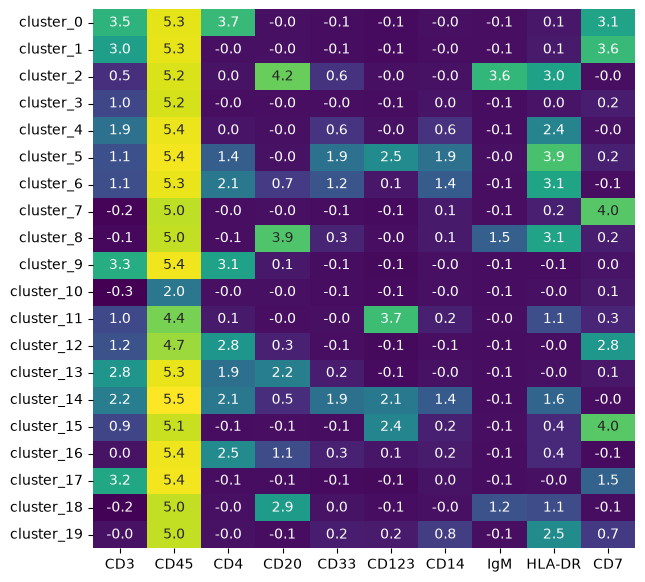

In [8]:
cluster_medians = sc.get.aggregate(adata[:, type_markers], by="cluster", func="median").to_df(layer="median")
fig, ax = plt.subplots(figsize=(7, 7))
sns.heatmap(cluster_medians, annot=True, fmt=".1f", cmap="viridis", cbar=False, ax=ax)
ax.set(xlabel="", ylabel="");

Rather than typing a name for every cluster number, we write down the marker profile of each population as a rule on these medians. The rules follow the usual definitions: B cells are CD20+, T cells CD3+ (and CD4+ or CD4-; we call the CD4- T cells CD8 T cells, although CD8 is not in the panel), NK cells CD7+ CD3-, monocytes HLA-DR+ with CD14 or CD33, dendritic cells (DC) HLA-DR+ without other lineage markers, and basophils CD123+ HLA-DR-. Myeloid cells have a background of up to about 2 in the CD3 channel of this panel, so their rules allow it. Each rule also requires the other lineage markers to be negative, so that clusters of doublets (for example CD3+ CD14+) match no rule.

The rules are written so that a cluster can match at most one of them, and the code stops with an error if a cluster matches two or if a population is not found at all. Clusters that match no rule are called `unassigned`: debris with low CD45, doublets and cells without a clear phenotype.

In [9]:
rules = {
    "B cells": "CD20 > 2 and CD3 < 1.5 and CD4 < 1.5 and CD7 < 1",
    "CD4 T": "CD3 > 2 and CD4 > 2 and CD20 < 1 and CD14 < 1 and CD33 < 1 and CD123 < 1",
    "CD8 T": "CD3 > 2 and CD4 < 1 and CD20 < 1 and CD14 < 1 and CD33 < 1 and CD123 < 1",
    "NK": "CD7 > 2 and CD3 < 1.5 and CD4 < 1 and CD20 < 1 and CD14 < 1 and CD123 < 1",
    "monocytes": "`HLA-DR` > 2 and (CD14 > 1 or CD33 > 1) and CD3 < 2 and CD20 < 1 and CD7 < 1",
    "DC": "`HLA-DR` > 2 and CD14 < 1 and CD33 < 1 and CD3 < 2 and CD20 < 1 and CD7 < 1",
    "basophils": "CD123 > 2 and `HLA-DR` < 2 and CD3 < 2 and CD20 < 1 and CD7 < 1",
}
matches = pd.DataFrame({name: cluster_medians.eval(f"CD45 > 3 and ({rule})") for name, rule in rules.items()})
assert matches.sum(axis=1).max() <= 1, "a cluster matches more than one rule"
assert matches.any(axis=0).all(), "a population was not found"
names = matches.idxmax(axis=1).where(matches.any(axis=1), "unassigned")
adata.obs["population"] = pd.Categorical(adata.obs["cluster"].map(names), categories=[*rules, "unassigned"])
adata.obs["population"].value_counts(normalize=True).round(3)

population
CD4 T         0.321
CD8 T         0.217
unassigned    0.182
NK            0.102
B cells       0.056
DC            0.055
monocytes     0.050
basophils     0.017
Name: proportion, dtype: float64

With other seeds (0, 1 and 7) the cluster numbers change completely, but these rules find the same populations in nearly the same proportions. We remove the unassigned cells before all further analyses, as a gating step:

In [10]:
adata = adata[adata.obs["population"] != "unassigned"].copy()
adata.obs["population"] = adata.obs["population"].cat.remove_unused_categories()
adata

AnnData object with n_obs × n_vars = 141262 × 24
    obs: 'sample_id', 'condition', 'patient_id', 'cluster', 'cluster_som_node', 'population'
    uns: 'cluster'
    layers: None (.X)

## Summarise each sample

Now we reduce the cells to one row per sample. For abundance, we count the cells of each population in each sample:

In [11]:
counts = pd.crosstab(adata.obs["sample_id"], adata.obs["population"])
counts.head()

population,B cells,CD4 T,CD8 T,NK,monocytes,DC,basophils
sample_id,,,,,,,
BCRXL1,144,701,1197,326,56,52,14
BCRXL2,401,5450,5905,1326,207,708,277
BCRXL3,758,3746,2054,1549,559,1326,301
BCRXL4,447,2684,1370,1188,475,968,267
BCRXL5,471,2706,2231,738,220,840,195


and divide by the number of cells per sample to get proportions:

In [12]:
proportions = counts.div(counts.sum(axis=1), axis=0)
proportions.round(3).head()

population,B cells,CD4 T,CD8 T,NK,monocytes,DC,basophils
sample_id,,,,,,,
BCRXL1,0.058,0.282,0.481,0.131,0.022,0.021,0.006
BCRXL2,0.028,0.382,0.414,0.093,0.015,0.050,0.019
BCRXL3,0.074,0.364,0.200,0.150,0.054,0.129,0.029
BCRXL4,0.060,0.363,0.185,0.161,0.064,0.131,0.036
BCRXL5,0.064,0.366,0.301,0.100,0.030,0.113,0.026


For the state markers, we take the median of each marker over the cells of each population in each sample, with `sc.get.aggregate`. This gives an AnnData with one observation per sample and population (16 x 7 = 112) and the medians in the layer `"median"`. Grouping also by condition and donor keeps both in `obs`.

In [13]:
pseudobulk = sc.get.aggregate(
    adata[:, state_markers],
    by=["sample_id", "population", "condition", "patient_id"],
    func="median",
)
pseudobulk

AnnData object with n_obs × n_vars = 112 × 14
    obs: 'sample_id', 'population', 'condition', 'patient_id', 'n_obs_aggregated'
    layers: 'median'

A median of very few cells is noisy. The samples of donor 1 have only about 2,500 cells each, and the smallest populations have few cells in some samples:

In [14]:
pseudobulk.obs.groupby("population", observed=True)["n_obs_aggregated"].min()

population
B cells      144
CD4 T        701
CD8 T        683
NK           285
monocytes     56
DC            27
basophils     10
Name: n_obs_aggregated, dtype: int64

## Do the type markers respond to the stimulation?

We clustered on the type markers on the assumption that they do not change with the stimulation. To check this, we compute the same per-sample medians for the type markers and average the difference between the stimulated and the reference sample of each donor:

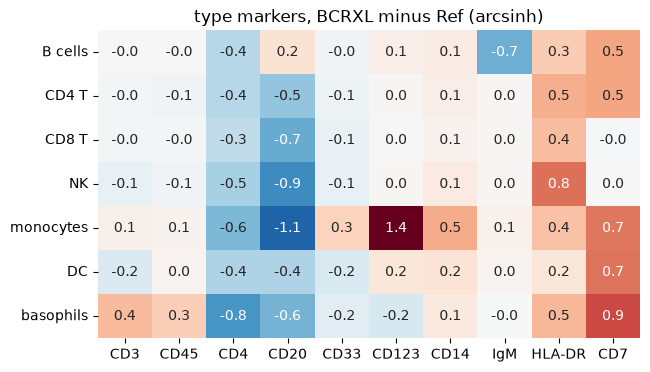

In [15]:
type_pseudobulk = sc.get.aggregate(
    adata[:, type_markers], by=["sample_id", "population", "condition", "patient_id"], func="median"
)
type_medians = type_pseudobulk.to_df(layer="median").join(type_pseudobulk.obs)
type_medians = type_medians.pivot_table(
    index=["population", "patient_id"], columns="condition", values=type_markers, observed=True
)
type_shift = (
    (type_medians.xs("BCRXL", axis=1, level=1) - type_medians.xs("Ref", axis=1, level=1)).groupby("population").mean()
)
type_shift = type_shift[type_markers]

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(type_shift, cmap="RdBu_r", center=0, annot=True, fmt=".1f", cbar=False, ax=ax)
ax.set(xlabel="", ylabel="", title="type markers, BCRXL minus Ref (arcsinh)");

Several type markers do shift: CD4 falls and HLA-DR rises in almost all populations, CD20 falls outside the B cells, CD7 rises in CD4 T cells, B cells and the myeloid cells, IgM falls in B cells and CD123 rises in monocytes. Clusters defined by such a marker are therefore not stable under this stimulus. If we had split CD4 T cells by CD7 or B cells by IgM, as the 20 clusters do, the shift would appear as a change in abundance between the subsets. This is why we only use broad populations here, and it is a reason to read the abundance results below with care.

## Differential abundance

Cell proportions are compositional: they add up to 1 in every sample, so when one population grows, all others shrink in proportion even if their absolute numbers do not change. Testing each population on its own ignores this. [scCODA](https://doi.org/10.1038/s41467-021-27150-6) models all populations of a sample together and measures every change relative to a reference population that is assumed not to change. It works well with few samples. We include the donor as a covariate, which accounts for the pairing.

pertpy's `Sccoda` builds the sample-level table from the cell-level AnnData itself, by counting the cells per sample and population as above:

In [16]:
sccoda = pt.tl.Sccoda()
sccoda_data = sccoda.load(
    adata,
    type="cell_level",
    generate_sample_level=True,
    cell_type_identifier="population",
    sample_identifier="sample_id",
    covariate_obs=["condition", "patient_id"],
)
# make Ref the baseline of the condition
sccoda_data["coda"].obs["condition"] = pd.Categorical(sccoda_data["coda"].obs["condition"], categories=["Ref", "BCRXL"])
sccoda_data

MuData object with n_obs × n_vars = 141278 × 31
  2 modalities
    rna:	141262 × 24
      obs:	'sample_id', 'condition', 'patient_id', 'cluster', 'cluster_som_node', 'population', 'scCODA_sample_id'
      uns:	'cluster'
      layers:	None
    coda:	16 × 7
      obs:	'sample_id', 'condition', 'patient_id'
      var:	'n_cells'
      layers:	None

The proportions of each population per sample, by condition:

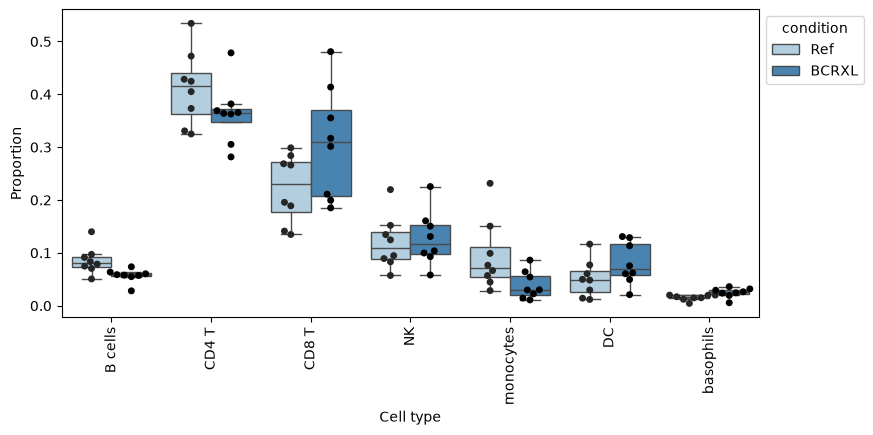

In [17]:
sccoda.plot_boxplots(sccoda_data, feature_name="condition", add_dots=True, figsize=(9, 4));

We use CD4 T cells as the reference: the largest population, which we do not expect to change within 30 minutes. The model formula `condition + patient_id` estimates the effect of the stimulation with the donor as a covariate. scCODA is a Bayesian model and is fitted by sampling, which takes a few minutes on a laptop.

In [18]:
sccoda_data = sccoda.prepare(sccoda_data, formula="condition + patient_id", reference_cell_type="CD4 T")
sccoda.run_nuts(sccoda_data, num_samples=5000, num_warmup=500, rng_key=1234)

scCODA calls an effect credible if it is included in the model with high probability, controlling the false discovery rate at 5% by default. The effects of the stimulation:

In [19]:
effects = sccoda.get_effect_df(sccoda_data).loc["condition[T.BCRXL]"]
effects["credible"] = sccoda.credible_effects(sccoda_data).loc["condition[T.BCRXL]"]
effects[["Inclusion probability", "log2-fold change", "credible"]].round(2)

,Inclusion probability,log2-fold change,credible
Cell Type,,,
B cells,0.61,-0.18,False
CD4 T,0.00,-0.18,False
CD8 T,0.99,0.42,True
NK,0.36,-0.18,False
monocytes,0.99,-1.31,True
DC,0.93,0.54,True
basophils,0.60,-0.18,False


Relative to CD4 T cells, the model finds fewer monocytes, and more CD8 T cells and DCs, in the stimulated samples. The non-credible populations still show a small common shift in `log2-fold change`, because the proportions have to add up to 1.

The two myeloid populations are told apart by CD14 and CD33, and their shares move in opposite directions. Together they change much less:

In [20]:
myeloid = proportions[["monocytes", "DC"]].assign(**{"monocytes + DC": lambda df: df.sum(axis=1)})
myeloid.groupby(metadata.set_index("sample_id")["condition"]).mean().round(3)

population,monocytes,DC,monocytes + DC
condition,,,
Ref,0.094,0.051,0.145
BCRXL,0.039,0.080,0.119


So a large part of the drop in monocytes is likely monocytes being classified as DCs after the stimulation, another consequence of type markers that respond to it. The other effects depend on the choices we made: with NK cells as the reference only the monocyte decrease is credible, and with other FlowSOM seeds the set of credible effects changes as well. The CyTOF workflow, with a different clustering and a paired count model per population, also reports more CD8 T cells and DCs after stimulation, but finds changes in NK, B and CD4 T cells and none in monocytes. After a 30 minute stimulation, cells are unlikely to have appeared or disappeared, and a credible change in abundance is a starting point for such questions, not an answer to them.

Other scverse options for abundance are a count model per population (for example `pt.tl.PyDESeq2` on the `counts` table) and pertpy's Milo, which tests neighbourhoods of a kNN graph instead of clusters.

## Differential state

For every population and state marker we now ask whether the per-sample median changes with stimulation. We fit a linear model `~ condition + patient_id` to the 16 medians of each population with pertpy's `Statsmodels`, through `compare_groups(..., paired_by="patient_id")`. With one sample per donor and condition, this is the same as a paired t-test: it tests whether the within-donor difference is zero on average. The coefficient, which pertpy reports as `log_fc`, is here the mean difference of the arcsinh-transformed medians (stimulated minus reference). For bright signals, a difference of 1 on the arcsinh scale is about a 2.7-fold change.

In [21]:
results = []
for population in pseudobulk.obs["population"].cat.categories:
    subset = pseudobulk[pseudobulk.obs["population"] == population]
    result = pt.tl.Statsmodels.compare_groups(
        subset,
        column="condition",
        baseline="Ref",
        groups_to_compare="BCRXL",
        paired_by="patient_id",
        layer="median",
    )
    results.append(result.assign(population=population))
results = pd.concat(results, ignore_index=True).rename(columns={"variable": "marker", "log_fc": "difference"})

`compare_groups` corrects the p-values only over the markers of one population. We tested 7 populations x 14 markers = 98 hypotheses, so we redo the Benjamini-Hochberg correction over all of them:

In [22]:
results["adj_p_value"] = fdrcorrection(results["p_value"])[1]
significant = results["adj_p_value"] < 0.05
large = results["difference"].abs() >= 0.5
print(f"{significant.sum()} of {len(results)} tests with adjusted p < 0.05")
print(f"{(significant & large).sum()} of them with a difference of at least 0.5")

68 of 98 tests with adjusted p < 0.05
24 of them with a difference of at least 0.5


With a paired design, even small but consistent differences become significant. The adjusted p-value tells us that a change is unlikely to be zero, not that it is large or biologically relevant. We therefore also require a difference of at least 0.5 on the arcsinh scale, and sort by its size:

In [23]:
results[significant & large].sort_values("difference", key=abs, ascending=False)[
    ["population", "marker", "difference", "adj_p_value"]
].head(10)

,population,marker,difference,adj_p_value
0,B cells,pS6,2.634119,0.000016
56,monocytes,pS6,1.767741,0.000037
1,B cells,pPlcg2,1.630857,0.000253
71,DC,pS6,1.298131,0.000695
3,B cells,pErk,1.211328,0.000612
70,DC,pNFkB,-1.156172,0.000636
29,CD8 T,pNFkB,-1.113716,0.001186
18,CD4 T,pNFkB,-0.988369,0.005601
43,NK,pNFkB,-0.947179,0.002029
22,CD4 T,pp38,-0.787966,0.026192


The heatmap shows the differences that pass both filters (red: higher after stimulation, blue: lower; blank: not significant or smaller than 0.5):

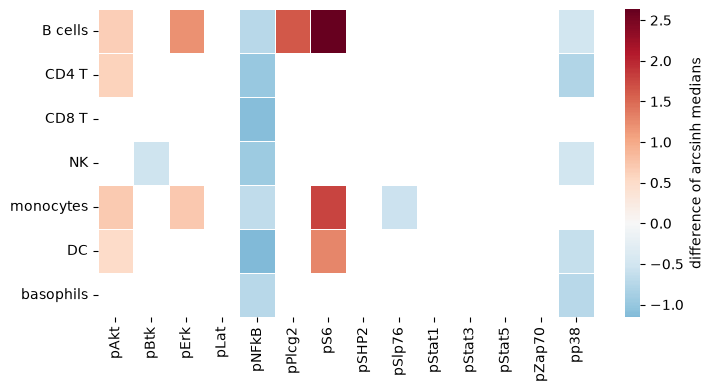

In [24]:
populations = pseudobulk.obs["population"].cat.categories
difference = results.pivot(index="population", columns="marker", values="difference").loc[populations]
adj_p = results.pivot(index="population", columns="marker", values="adj_p_value").loc[populations]
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(
    difference.where((adj_p < 0.05) & (difference.abs() >= 0.5)),
    cmap="RdBu_r",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "difference of arcsinh medians"},
    ax=ax,
)
ax.set(xlabel="", ylabel="");

The largest changes are increases of pS6, pPlcg2 and pErk in B cells. These proteins are part of the signalling downstream of the B cell receptor, so this is the response we expect from a B cell receptor cross-linker. pS6 also rises in monocytes and DCs, which carry Fc receptors that the cross-linker may engage as well. The paired plot shows the B cell changes in each donor:

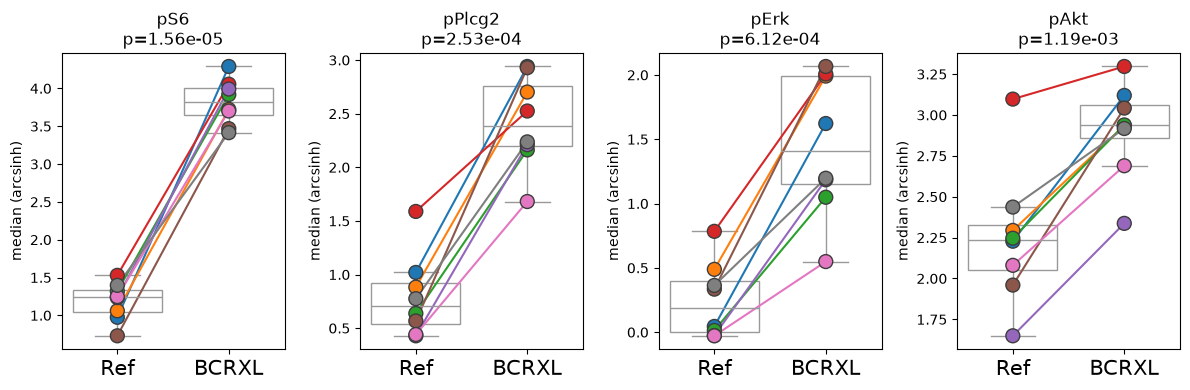

In [25]:
b_cells = pseudobulk[pseudobulk.obs["population"] == "B cells"]
model = pt.tl.Statsmodels(b_cells, design="~ condition + patient_id", layer="median")
model.plot_paired(
    b_cells,
    results[results["population"] == "B cells"],
    groupby="condition",
    pairedby="patient_id",
    var_names=["pS6", "pPlcg2", "pErk", "pAkt"],
    layer="median",
    symbol_col="marker",
    y_label="median (arcsinh)",
    n_cols=4,
    panel_size=(3, 4),
    show_legend=False,
);

Other changes are not specific to B cells. pAkt rises in all seven populations (by 0.3 to 0.7), pNFkB falls in all of them (by 0.7 to 1.2) and pp38 falls in most. pBtk falls in all populations and pSlp76 in all except B cells, to around background, so their differences are mostly below 0.5 but very consistent. The CyTOF workflow reports the same: in its test on the medians of all cells, pBtk, pSlp76 and pNFkB (down) and pAkt and pS6 (up) are the five strongest changes. A drop of pBtk in all cell types is not what B cell receptor signalling alone would predict, and this data cannot tell us its cause. Effects that are specific to the cells the stimulus targets, like pS6 in B cells, are easier to interpret.

## Session info

In [26]:
import session_info2

session_info2.session_info()

Package,Version
pandas,3.1.0
arviz-stats,1.3.3
matplotlib,3.11.2
anndata,0.13.4
pertpy,1.4.0
pooch,1.9.0 (v1.9.0)
scanpy,1.12.4
seaborn,0.13.2
statsmodels,0.15.0
pytometry,0.2.0
